# Experiment 8 — Cross-embodiment transfer of a manipulation skill (PyBullet)
CSAI4014 AISR Laboratory

**Question:** can a pick-and-place skill developed on one arm (KUKA iiwa) be moved to arms with different
kinematics, numbers of joints and size? Four embodiments, all from `pybullet_data`:

| robot | DOF | notes |
|---|---|---|
| kuka_iiwa | 7 | source robot |
| franka_panda | 7 | different link lengths and joint limits |
| xarm6 | 6 | one joint fewer |
| kuka_mini | 7 | KUKA scaled to 75 % (capability gap: shorter reach) |

Parts: (1) embodiments and workspace, (2) joint-space replay of KUKA trajectories, (3) task-space transfer of
the expert, (4) learn on KUKA (behaviour cloning) and deploy everywhere, (5) leave-one-embodiment-out
multi-embodiment training, plus two exercises (DART noise, IK rest pose).

Simplifications (stated in the report): arms are moved kinematically (rate-limited joint updates) and the gripper
is an abstract binary open/close that grasps when the closed gripper is within 3 cm of the cube. Everything else
(URDF kinematics, joint limits, IK) is PyBullet. Install once with `pip install pybullet`.
Results: CSV files in `results/`, figures in `results/` and `figs/`, numbers in `results.json`.

In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

os.makedirs('results', exist_ok=True)
try:
    import pybullet
except ImportError:
    %pip install --upgrade pybullet
import pybullet
RESULTS['env']['pybullet'] = pybullet.getAPIVersion()

{'python': '3.12.1', 'numpy': '2.3.2', 'matplotlib': '3.8.4', 'os': 'Windows 11', 'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'scipy': '1.16.1'}


## 0. Robots, task and the abstract gripper

In [2]:
import time, csv
import numpy as np
import pybullet as p
import pybullet_data

# ---------------------------------------------------------------- robots
ROBOTS = {   # name: (urdf, global scaling, end-effector link index)
    "kuka_iiwa":    ("kuka_iiwa/model.urdf", 1.00, 6),
    "franka_panda": ("franka_panda/panda.urdf", 1.00, 11),
    "xarm6":        ("xarm/xarm6_robot.urdf", 1.00, 6),
    "kuka_mini":    ("kuka_iiwa/model.urdf", 0.75, 6),
}
DOWN = p.getQuaternionFromEuler([np.pi, 0, 0])      # gripper pointing down
TABLE_Z = 0.0
CUBE_HALF = 0.02
PICK_X, PICK_Y = (0.45, 0.65), (-0.20, 0.00)        # cube spawn region (m)
GOAL_X, GOAL_Y = (0.40, 0.60), (0.10, 0.25)         # place region (m)
HOVER_Z, GRASP_Z, PLACE_Z = 0.20, 0.045, 0.07       # end-effector heights (m)
MAX_STEP = 0.02                                     # max EE displacement per step (m)
MAX_DQ = 0.20                                       # max joint change per step (rad)
SUCCESS_TOL = 0.03                                  # cube within 3 cm of goal (xy)


class Arm:
    """A fixed-base arm with a kinematic 'abstract gripper' and a cube.

    Joints are moved kinematically (resetJointState, rate-limited), the gripper is
    a binary open/close command and a grasp succeeds when the closed gripper is
    within 3 cm of the cube. This keeps every robot identical except its body.
    """
    def __init__(self, name, use_rest_pose=True):
        self.name = name
        urdf, scale, self.ee = ROBOTS[name]
        self.cid = p.connect(p.DIRECT)
        p.setAdditionalSearchPath(pybullet_data.getDataPath(), physicsClientId=self.cid)
        self.body = p.loadURDF(urdf, useFixedBase=True, globalScaling=scale, physicsClientId=self.cid)
        nj = p.getNumJoints(self.body, physicsClientId=self.cid)
        info = [p.getJointInfo(self.body, j, physicsClientId=self.cid) for j in range(nj)]
        self.movable = [j for j in range(nj) if info[j][2] != p.JOINT_FIXED]
        self.arm = [j for j in self.movable if info[j][2] == p.JOINT_REVOLUTE][:7]
        self.dof = len(self.arm)
        lo = np.array([info[j][8] for j in self.movable]); hi = np.array([info[j][9] for j in self.movable])
        bad = hi <= lo; lo[bad], hi[bad] = -np.pi, np.pi
        self.lo, self.hi = lo, hi
        self.rest = np.clip((lo + hi) / 2, lo, hi)
        self.rest[: self.dof] = self._home_guess()
        self.use_rest_pose = use_rest_pose
        col = p.createCollisionShape(p.GEOM_BOX, halfExtents=[CUBE_HALF] * 3, physicsClientId=self.cid)
        self.cube = p.createMultiBody(0, col, basePosition=[0.5, 0, CUBE_HALF], physicsClientId=self.cid)

    def _home_guess(self):
        # elbow-up "ready" posture used as IK rest pose / null-space target
        g = {"kuka_iiwa": [0, 0.6, 0, -1.2, 0, 1.3, 0], "kuka_mini": [0, 0.6, 0, -1.2, 0, 1.3, 0],
             "franka_panda": [0, 0.2, 0, -2.0, 0, 2.2, 0.8], "xarm6": [0, -0.3, -1.2, 0, 1.5, 0]}
        return np.array(g[self.name][: self.dof])

    # ---------- kinematics ----------
    def q(self):
        return np.array([p.getJointState(self.body, j, physicsClientId=self.cid)[0] for j in self.arm])

    def set_q(self, q):
        for j, v in zip(self.arm, q):
            p.resetJointState(self.body, j, float(v), physicsClientId=self.cid)

    def ee_pos(self):
        return np.array(p.getLinkState(self.body, self.ee, computeForwardKinematics=True,
                                       physicsClientId=self.cid)[4])

    def ik(self, target):
        kw = dict(maxNumIterations=100, residualThreshold=1e-4, physicsClientId=self.cid)
        if self.use_rest_pose:
            kw.update(lowerLimits=self.lo.tolist(), upperLimits=self.hi.tolist(),
                      jointRanges=(self.hi - self.lo).tolist(), restPoses=self.rest.tolist())
        sol = p.calculateInverseKinematics(self.body, self.ee, list(target), DOWN, **kw)
        return np.clip(np.array(sol[: self.dof]), self.lo[: self.dof], self.hi[: self.dof])

    def reach_error(self, target):
        """Position error of the IK solution for a downward-pointing gripper (m)."""
        q0 = self.q()
        self.set_q(self.rest[: self.dof])
        for _ in range(3):                      # a few refinements
            self.set_q(self.ik(target))
        err = float(np.linalg.norm(self.ee_pos() - np.array(target)))
        self.set_q(q0)
        return err

    # ---------- episode ----------
    def reset(self, rng):
        self.set_q(self.rest[: self.dof])
        self.cube_pos = np.array([rng.uniform(*PICK_X), rng.uniform(*PICK_Y), TABLE_Z + CUBE_HALF])
        self.goal = np.array([rng.uniform(*GOAL_X), rng.uniform(*GOAL_Y), TABLE_Z + CUBE_HALF])
        self.closed, self.grasped, self.t = False, False, 0
        self._sync_cube()
        return self.obs()

    def _sync_cube(self):
        p.resetBasePositionAndOrientation(self.cube, self.cube_pos.tolist(), [0, 0, 0, 1], physicsClientId=self.cid)

    def _gripper(self, close):
        ee = self.ee_pos()
        if close and not self.closed and not self.grasped:
            if np.linalg.norm(ee - (self.cube_pos + [0, 0, GRASP_Z - CUBE_HALF])) < 0.03:
                self.grasped = True
        if not close and self.grasped:          # release: cube drops onto the table below the gripper
            self.grasped = False
            self.cube_pos = np.array([ee[0], ee[1], TABLE_Z + CUBE_HALF])
        self.closed = bool(close)
        if self.grasped:
            self.cube_pos = ee - np.array([0, 0, GRASP_Z - CUBE_HALF])
        self._sync_cube()

    def step_task(self, d_ee, close):
        """Task-space action: EE displacement (clipped to 2 cm) + binary gripper command."""
        d = np.clip(np.asarray(d_ee, float), -MAX_STEP, MAX_STEP)
        q_target = self.ik(self.ee_pos() + d)
        self.set_q(self.q() + np.clip(q_target - self.q(), -MAX_DQ, MAX_DQ))
        self._gripper(close); self.t += 1
        return self.obs()

    def step_joint(self, q, close):
        """Joint-space action: absolute joint angles (rate-limited) + gripper command."""
        q = np.asarray(q, float)
        self.set_q(self.q() + np.clip(q - self.q(), -MAX_DQ, MAX_DQ))
        self._gripper(close); self.t += 1
        return self.obs()

    def obs(self):
        return {"ee": self.ee_pos(), "cube": self.cube_pos.copy(), "goal": self.goal.copy(),
                "closed": float(self.closed), "q": self.q()}

    def cube_goal_error(self):
        return float(np.linalg.norm(self.cube_pos[:2] - self.goal[:2]))

    def success(self):
        return (not self.grasped) and self.cube_goal_error() < SUCCESS_TOL and self.cube_pos[2] < 0.03

## 0b. The scripted expert (task space only)

In [3]:
# ---------------------------------------------------------------- scripted expert
class Expert:
    """Task-space expert. Its action depends only on the current observation (no hidden
    phase), so it can be cloned: a 'funnel' lowers the gripper as it closes in on the target."""
    def act(self, o):
        ee, cube, goal, closed = o["ee"], o["cube"], o["goal"], o["closed"] > 0.5
        at_goal = np.linalg.norm(cube[:2] - goal[:2]) < 0.02
        if not closed and at_goal:                          # placed: retreat upwards
            if ee[2] > HOVER_Z - 0.01:
                return np.zeros(3), 0, True
            return np.clip(np.r_[0, 0, HOVER_Z - ee[2]], -MAX_STEP, MAX_STEP), 0, False
        if not closed:                                      # go and grasp the cube
            xy = cube[:2] - ee[:2]; e = np.linalg.norm(xy)
            target = np.r_[cube[:2], GRASP_Z + min(HOVER_Z - GRASP_Z, 6 * e)]
            near = np.linalg.norm(target - ee) < 0.015 and e < 0.01
            return np.clip(target - ee, -MAX_STEP, MAX_STEP), int(near), False
        xy = goal[:2] - ee[:2]; e = np.linalg.norm(xy)      # carry the cube to the goal
        target = np.r_[goal[:2], PLACE_Z + min(HOVER_Z - PLACE_Z, 6 * e)]
        near = np.linalg.norm(target - ee) < 0.015 and e < 0.01
        return np.clip(target - ee, -MAX_STEP, MAX_STEP), int(not near), False


def run_expert(arm, rng, max_steps=160, noise=0.0, record=False):
    """Run the task-space expert on any arm. Optional DART noise on the executed action."""
    o = arm.reset(rng); ex = Expert(); log = []
    for _ in range(max_steps):
        a, g, done = ex.act(o)
        if done:
            break
        if record:
            log.append((o, a.copy(), g))
        a_exec = a + (rng.normal(0, noise, 3) if noise > 0 else 0)
        o = arm.step_task(a_exec, g)
    return arm.success(), arm.t, arm.cube_goal_error(), log

## 0c. Joint-space replay and behaviour cloning code

In [4]:
# ---------------------------------------------------------------- joint-space replay
def map_joints(q_src, dof):
    """Naive joint mapping: copy the first `dof` angles, pad with zeros if needed."""
    out = np.zeros(dof); k = min(dof, len(q_src)); out[:k] = q_src[:k]; return out


def replay_joint_space(src, dst, seed):
    """Record a KUKA expert episode, replay its joint angles on `dst` with the same cube/goal."""
    s_ok, _, _, log = run_expert(src, np.random.default_rng(seed), record=True)
    q_traj = [o["q"] for o, _, _ in log] + [src.q()]
    g_traj = [g for _, _, g in log] + [0]
    src_path = np.array([o["ee"] for o, _, _ in log])
    dst.reset(np.random.default_rng(seed))                 # same cube and goal
    path = []
    for q, g in zip(q_traj, g_traj):
        dst.step_joint(map_joints(q, dst.dof), g); path.append(dst.ee_pos())
    path = np.array(path)[: len(src_path)]
    dev = float(np.mean(np.linalg.norm(path - src_path[: len(path)], axis=1)))
    return dst.success(), dev, dst.cube_goal_error(), src_path, path

In [5]:
# ---------------------------------------------------------------- behaviour cloning
def features(o, proprio=False):
    """Embodiment-agnostic observation (task space), optionally + joint angles padded to 7."""
    f = np.r_[o["cube"] - o["ee"], o["goal"] - o["ee"], o["goal"][:2] - o["cube"][:2], o["ee"][2], o["closed"]]
    if proprio:
        f = np.r_[f, map_joints(o["q"], 7)]
    return f


def collect(arm, n_eps, seed, noise=0.01):
    rng = np.random.default_rng(seed); X, Y = [], []
    for _ in range(n_eps):
        _, _, _, log = run_expert(arm, rng, noise=noise, record=True)
        for o, a, g in log:
            X.append(o); Y.append(np.r_[a / MAX_STEP, g])
    return X, np.array(Y)


class MLP:
    """Two hidden layers (64, tanh), Adam, MSE. NumPy only."""
    def __init__(self, n_in, n_out, seed=0, h=64):
        r = np.random.default_rng(seed)
        self.P = [r.normal(0, 1/np.sqrt(n_in), (n_in, h)), np.zeros(h), r.normal(0, 1/np.sqrt(h), (h, h)),
                  np.zeros(h), r.normal(0, 1/np.sqrt(h), (h, n_out)), np.zeros(n_out)]

    def forward(self, X):
        W1, b1, W2, b2, W3, b3 = self.P
        h1 = np.tanh(X @ W1 + b1); h2 = np.tanh(h1 @ W2 + b2)
        return h1, h2, h2 @ W3 + b3

    def fit(self, X, Y, epochs=300, lr=3e-3, bs=256, seed=0):
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-6
        Xn = (X - self.mu) / self.sd; r = np.random.default_rng(seed)
        m = [np.zeros_like(w) for w in self.P]; v = [np.zeros_like(w) for w in self.P]; t = 0
        for _ in range(epochs):
            idx = r.permutation(len(Xn))
            for k in range(0, len(idx), bs):
                b = idx[k:k + bs]; x, y = Xn[b], Y[b]
                h1, h2, out = self.forward(x)
                d3 = 2 * (out - y) / len(b)
                W1, b1, W2, b2, W3, b3 = self.P
                d2 = (d3 @ W3.T) * (1 - h2**2); d1 = (d2 @ W2.T) * (1 - h1**2)
                grads = [x.T @ d1, d1.sum(0), h1.T @ d2, d2.sum(0), h2.T @ d3, d3.sum(0)]
                t += 1
                for i, g in enumerate(grads):
                    m[i] = 0.9*m[i] + 0.1*g; v[i] = 0.999*v[i] + 0.001*g*g
                    self.P[i] -= lr * (m[i]/(1-0.9**t)) / (np.sqrt(v[i]/(1-0.999**t)) + 1e-8)
        return self

    def predict(self, x):
        return self.forward((x - self.mu) / self.sd)[2]


def train_policy(obs, Y, proprio, seed=0, oversample=20):
    """Behaviour cloning. Gripper open/close events are rare (about 2 samples per episode),
    so samples where the gripper command changes state are repeated `oversample` times."""
    X = np.array([features(o, proprio) for o in obs])
    event = np.array([(y[3] > 0.5) != (o["closed"] > 0.5) for o, y in zip(obs, Y)])
    idx = np.r_[np.arange(len(X)), np.repeat(np.where(event)[0], oversample)]
    return MLP(X.shape[1], 4, seed).fit(X[idx], Y[idx], seed=seed)


def run_policy(arm, pol, proprio, rng, max_steps=160):
    o = arm.reset(rng)
    for _ in range(max_steps):
        out = pol.predict(features(o, proprio)[None])[0]
        o = arm.step_task(out[:3] * MAX_STEP, out[3] > 0.5)
        if arm.success() and o["ee"][2] > PLACE_Z + 0.03:
            break
    return arm.success()


def success_rate(fn, n, seed):
    rng = np.random.default_rng(seed)
    return float(np.mean([fn(rng) for _ in range(n)]))

In [6]:
def save_both(fig, name):
    fig.savefig(os.path.join("results", name), bbox_inches="tight"); save(fig, name)

def write_csv(name, rows):
    fields = []
    for r in rows:
        for k in r.keys():
            if k not in fields:
                fields.append(k)
    with open(os.path.join("results", name), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields); w.writeheader(); w.writerows(rows)

N_EVAL = 30                     # evaluation episodes per robot and method
ARMS = {n: Arm(n) for n in ROBOTS}
NAMES = list(ROBOTS)
print({n: ARMS[n].dof for n in NAMES})

{'kuka_iiwa': 7, 'franka_panda': 7, 'xarm6': 6, 'kuka_mini': 7}


## Part 1 — Embodiments: workspace and task coverage

{'robot': 'kuka_iiwa', 'dof': 7, 'max_reach_m': 1.257, 'task_coverage_pct': 100.0}


{'robot': 'franka_panda', 'dof': 7, 'max_reach_m': 1.276, 'task_coverage_pct': 100.0}


{'robot': 'xarm6', 'dof': 6, 'max_reach_m': 1.029, 'task_coverage_pct': 100.0}


{'robot': 'kuka_mini', 'dof': 7, 'max_reach_m': 0.943, 'task_coverage_pct': 66.0}


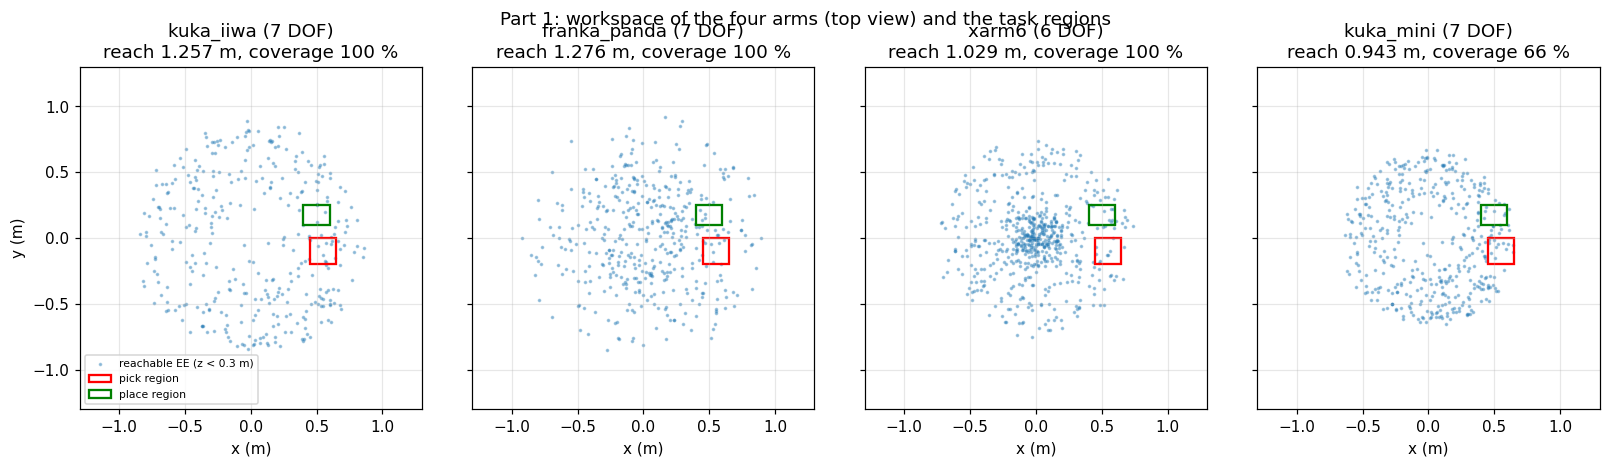

In [7]:
rng = np.random.default_rng(0)
task_pts = [[rng.uniform(*PICK_X), rng.uniform(*PICK_Y), z] for z in (GRASP_Z, HOVER_Z) for _ in range(25)] + \
           [[rng.uniform(*GOAL_X), rng.uniform(*GOAL_Y), z] for z in (PLACE_Z, HOVER_Z) for _ in range(25)]
part1, clouds = [], {}
for n in NAMES:
    arm = ARMS[n]; r = np.random.default_rng(1); pts = []
    for _ in range(1500):                                   # random joint configurations -> FK
        arm.set_q(r.uniform(arm.lo[:arm.dof], arm.hi[:arm.dof])); pts.append(arm.ee_pos())
    pts = np.array(pts); clouds[n] = pts
    reach = float(np.max(np.linalg.norm(pts, axis=1)))
    cov = float(np.mean([arm.reach_error(t) < 0.01 for t in task_pts]))
    part1.append({"robot": n, "dof": arm.dof, "max_reach_m": round(reach, 3), "task_coverage_pct": round(100*cov, 1)})
    print(part1[-1])
write_csv("01_embodiments.csv", part1); RESULTS["part1"] = part1

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharex=True, sharey=True)
for ax, n in zip(axes, NAMES):
    pts = clouds[n]; low = pts[:, 2] < 0.3
    ax.scatter(pts[low, 0], pts[low, 1], s=2, alpha=0.35, label="reachable EE (z < 0.3 m)")
    ax.add_patch(plt.Rectangle((PICK_X[0], PICK_Y[0]), np.ptp(PICK_X), np.ptp(PICK_Y), fill=False, ec="r", lw=1.5, label="pick region"))
    ax.add_patch(plt.Rectangle((GOAL_X[0], GOAL_Y[0]), np.ptp(GOAL_X), np.ptp(GOAL_Y), fill=False, ec="g", lw=1.5, label="place region"))
    row = next(r for r in part1 if r["robot"] == n)
    ax.set(title=f"{n} ({row['dof']} DOF)\nreach {row['max_reach_m']} m, coverage {row['task_coverage_pct']:.0f} %",
           xlabel="x (m)", xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal")
axes[0].set_ylabel("y (m)"); axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Part 1: workspace of the four arms (top view) and the task regions")
fig.tight_layout(); save_both(fig, "01_workspace.png"); plt.show()

## Part 2 — Joint-space replay of KUKA trajectories

{'robot': 'kuka_iiwa', 'success_pct': np.float64(100.0), 'mean_path_dev_cm': np.float64(0.0), 'median_cube_goal_err_cm': np.float64(0.2)}


{'robot': 'franka_panda', 'success_pct': np.float64(0.0), 'mean_path_dev_cm': np.float64(19.8), 'median_cube_goal_err_cm': np.float64(27.1)}


{'robot': 'xarm6', 'success_pct': np.float64(0.0), 'mean_path_dev_cm': np.float64(56.0), 'median_cube_goal_err_cm': np.float64(27.1)}


{'robot': 'kuka_mini', 'success_pct': np.float64(0.0), 'mean_path_dev_cm': np.float64(14.3), 'median_cube_goal_err_cm': np.float64(27.1)}


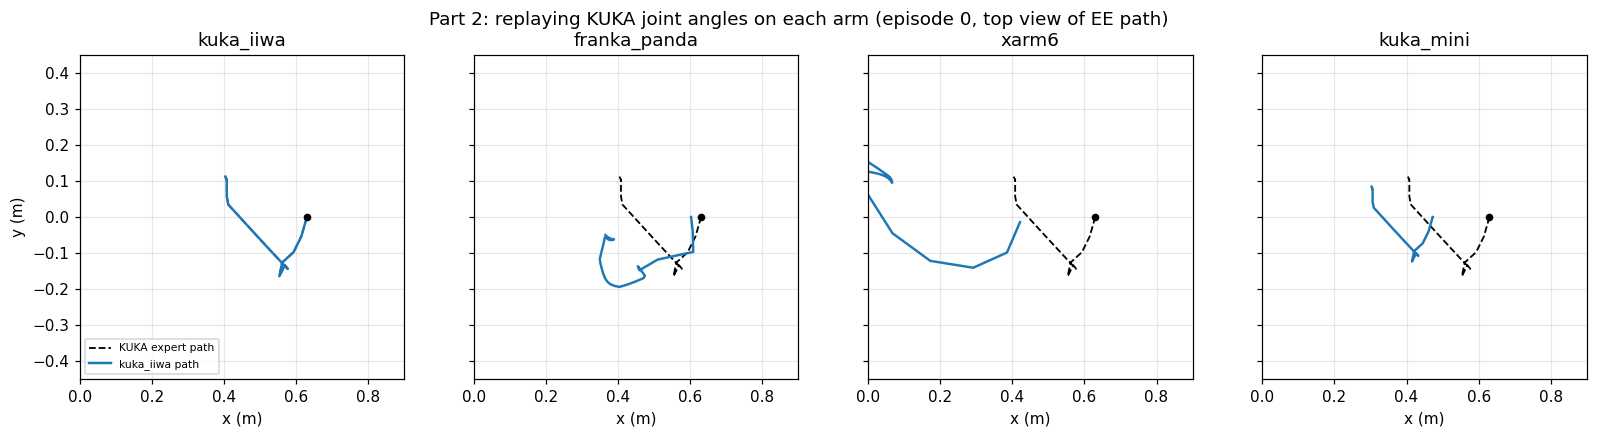

In [8]:
part2, paths2 = [], {}
for n in NAMES:
    res = [replay_joint_space(ARMS["kuka_iiwa"], ARMS[n], seed) for seed in range(N_EVAL)]
    paths2[n] = res[0][3:]
    part2.append({"robot": n, "success_pct": round(100*np.mean([r[0] for r in res]), 1),
                  "mean_path_dev_cm": round(100*np.mean([r[1] for r in res]), 1),
                  "median_cube_goal_err_cm": round(100*np.median([r[2] for r in res]), 1)})
    print(part2[-1])
write_csv("02_joint_space.csv", part2); RESULTS["part2"] = part2

def path_figure(paths, title, fname):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True)
    for ax, n in zip(axes, NAMES):
        ref, got = paths[n]
        ax.plot(ref[:, 0], ref[:, 1], "k--", lw=1.2, label="KUKA expert path")
        ax.plot(got[:, 0], got[:, 1], lw=1.6, label=f"{n} path")
        ax.plot(*ref[0, :2], "ko", ms=4)
        ax.set(title=n, xlabel="x (m)", aspect="equal", xlim=(0.0, 0.9), ylim=(-0.45, 0.45))
    axes[0].set_ylabel("y (m)"); axes[0].legend(fontsize=7, loc="lower left")
    fig.suptitle(title); fig.tight_layout(); save_both(fig, fname); plt.show()

path_figure(paths2, "Part 2: replaying KUKA joint angles on each arm (episode 0, top view of EE path)",
            "02_joint_space_paths.png")

## Part 3 — Task-space transfer of the expert

{'robot': 'kuka_iiwa', 'success_pct': np.float64(100.0), 'mean_steps_successful': 38.5, 'median_cube_goal_err_cm': np.float64(0.2)}


{'robot': 'franka_panda', 'success_pct': np.float64(100.0), 'mean_steps_successful': 38.3, 'median_cube_goal_err_cm': np.float64(0.1)}


{'robot': 'xarm6', 'success_pct': np.float64(100.0), 'mean_steps_successful': 50.6, 'median_cube_goal_err_cm': np.float64(0.1)}


{'robot': 'kuka_mini', 'success_pct': np.float64(40.0), 'mean_steps_successful': 43.1, 'median_cube_goal_err_cm': np.float64(20.5)}


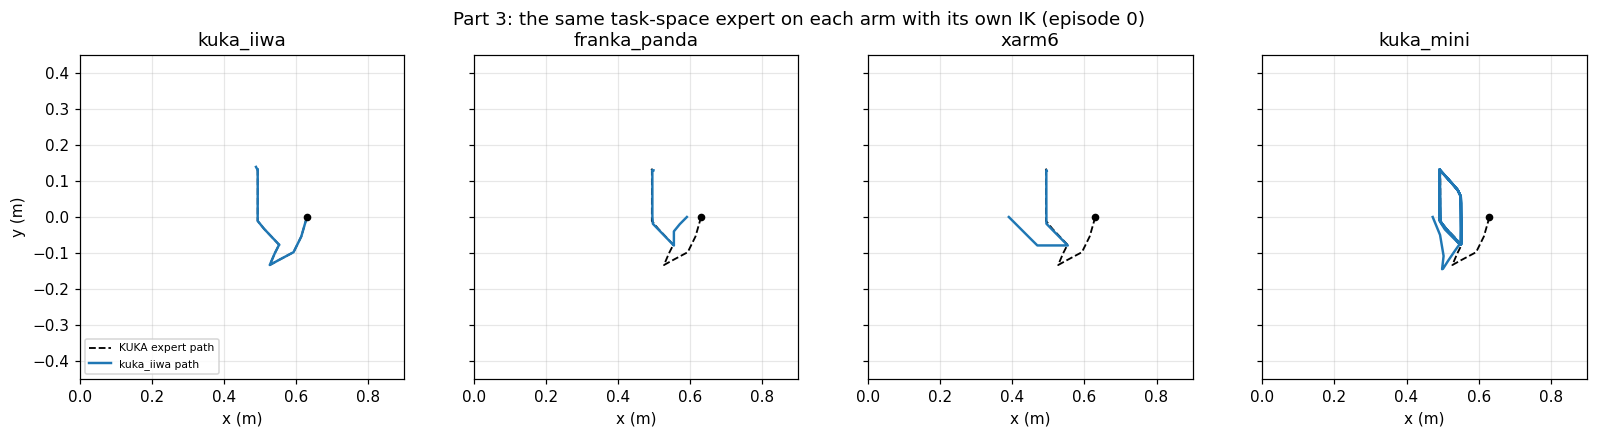

In [9]:
part3, paths3 = [], {}
for n in NAMES:
    rng = np.random.default_rng(1000); res = []
    for k in range(N_EVAL):
        ok, steps, err, log = run_expert(ARMS[n], rng, record=True)
        res.append((ok, steps, err))
        if k == 0:
            paths3[n] = (np.array([o["ee"] for o, _, _ in log]), np.array([o["ee"] for o, _, _ in log]))
    ok_steps = [s for o, s, _ in res if o]
    part3.append({"robot": n, "success_pct": round(100*np.mean([r[0] for r in res]), 1),
                  "mean_steps_successful": round(float(np.mean(ok_steps)), 1) if ok_steps else None,
                  "median_cube_goal_err_cm": round(100*np.median([r[2] for r in res]), 1)})
    print(part3[-1])
write_csv("03_task_space.csv", part3); RESULTS["part3"] = part3
ref = paths3["kuka_iiwa"][0]
path_figure({n: (ref, paths3[n][1]) for n in NAMES},
            "Part 3: the same task-space expert on each arm with its own IK (episode 0)", "03_task_space_paths.png")

## Part 4 — Learn once on KUKA, deploy everywhere
Behaviour cloning (BC) from 150 KUKA expert demonstrations with DART noise injection (σ = 1 cm on the executed
action, clean expert label recorded). Two observation designs:
* **BC-agnostic:** task-space only (cube − EE, goal − EE, goal − cube, EE height, gripper state).
* **BC-proprio:** the same plus the 7 joint angles (zero-padded for the 6-DOF xArm).

23374 KUKA samples collected in 28 s


{'robot': 'kuka_iiwa', 'expert_pct': 100.0, 'bc_agnostic_pct': 100.0, 'bc_proprio_pct': 100.0}


{'robot': 'franka_panda', 'expert_pct': 100.0, 'bc_agnostic_pct': 100.0, 'bc_proprio_pct': 0.0}


{'robot': 'xarm6', 'expert_pct': 100.0, 'bc_agnostic_pct': 100.0, 'bc_proprio_pct': 0.0}


{'robot': 'kuka_mini', 'expert_pct': 36.7, 'bc_agnostic_pct': 33.3, 'bc_proprio_pct': 16.7}


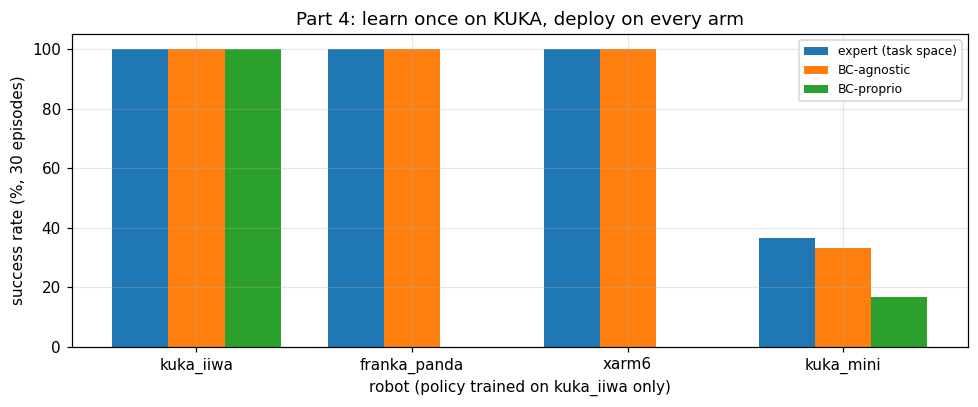

In [10]:
t0 = time.time()
DEMOS = {"kuka_iiwa": collect(ARMS["kuka_iiwa"], 150, seed=100, noise=0.01)}
print(f"{len(DEMOS['kuka_iiwa'][1])} KUKA samples collected in {time.time()-t0:.0f} s")
pol_agn = train_policy(*DEMOS["kuka_iiwa"], proprio=False)
pol_pro = train_policy(*DEMOS["kuka_iiwa"], proprio=True)

part4 = []
for n in NAMES:
    row = {"robot": n,
           "expert_pct": round(100*success_rate(lambda r: run_expert(ARMS[n], r)[0], N_EVAL, 7), 1),
           "bc_agnostic_pct": round(100*success_rate(lambda r: run_policy(ARMS[n], pol_agn, False, r), N_EVAL, 7), 1),
           "bc_proprio_pct": round(100*success_rate(lambda r: run_policy(ARMS[n], pol_pro, True, r), N_EVAL, 7), 1)}
    part4.append(row); print(row)
write_csv("04_learn_once_deploy_many.csv", part4); RESULTS["part4"] = part4

x = np.arange(len(NAMES)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (k, lab) in enumerate((("expert_pct", "expert (task space)"), ("bc_agnostic_pct", "BC-agnostic"),
                              ("bc_proprio_pct", "BC-proprio"))):
    ax.bar(x + (i-1)*w, [r[k] for r in part4], w, label=lab)
ax.set_xticks(x); ax.set_xticklabels(NAMES)
ax.set(ylabel=f"success rate (%, {N_EVAL} episodes)", ylim=(0, 105), xlabel="robot (policy trained on kuka_iiwa only)",
       title="Part 4: learn once on KUKA, deploy on every arm")
ax.legend(fontsize=8)
fig.tight_layout(); save_both(fig, "04_learn_once_deploy_many.png"); plt.show()

## Part 5 — Leave-one-embodiment-out (success on the unseen robot)

{'unseen': 'kuka_iiwa', 'single_source': 'franka_panda', 'multi_sources': 'franka_panda+xarm6', 'single_agnostic_pct': 100.0, 'single_proprio_pct': 0.0, 'multi_agnostic_pct': 100.0, 'multi_proprio_pct': 0.0}


{'unseen': 'franka_panda', 'single_source': 'kuka_iiwa', 'multi_sources': 'kuka_iiwa+xarm6', 'single_agnostic_pct': 100.0, 'single_proprio_pct': 0.0, 'multi_agnostic_pct': 100.0, 'multi_proprio_pct': 33.3}


{'unseen': 'xarm6', 'single_source': 'kuka_iiwa', 'multi_sources': 'kuka_iiwa+franka_panda', 'single_agnostic_pct': 93.3, 'single_proprio_pct': 0.0, 'multi_agnostic_pct': 100.0, 'multi_proprio_pct': 0.0}


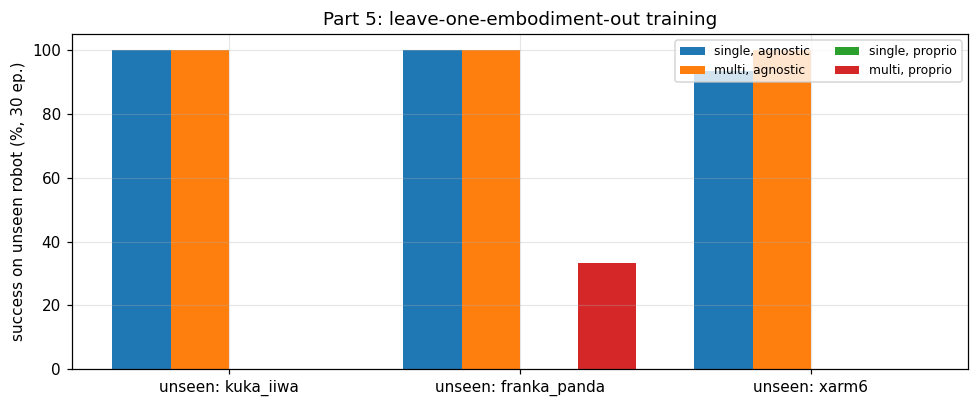

In [11]:
POOL = ["kuka_iiwa", "franka_panda", "xarm6"]
for n in POOL:
    if n not in DEMOS:
        DEMOS[n] = collect(ARMS[n], 150, seed=200 + POOL.index(n), noise=0.01)

def merge(names):
    obs = sum((DEMOS[n][0] for n in names), []); Y = np.vstack([DEMOS[n][1] for n in names])
    return obs, Y

part5 = []
for unseen in POOL:
    seen = [n for n in POOL if n != unseen]
    single = "kuka_iiwa" if unseen != "kuka_iiwa" else "franka_panda"
    row = {"unseen": unseen, "single_source": single, "multi_sources": "+".join(seen)}
    for tag, src in (("single", [single]), ("multi", seen)):
        for prop in (False, True):
            pol = train_policy(*merge(src), proprio=prop)
            key = f"{tag}_{'proprio' if prop else 'agnostic'}_pct"
            row[key] = round(100*success_rate(lambda r: run_policy(ARMS[unseen], pol, prop, r), N_EVAL, 11), 1)
    part5.append(row); print(row)
write_csv("05_multi_embodiment.csv", part5); RESULTS["part5"] = part5

keys = [("single_agnostic_pct", "single, agnostic"), ("multi_agnostic_pct", "multi, agnostic"),
        ("single_proprio_pct", "single, proprio"), ("multi_proprio_pct", "multi, proprio")]
x = np.arange(len(POOL)); w = 0.2
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (k, lab) in enumerate(keys):
    ax.bar(x + (i-1.5)*w, [r[k] for r in part5], w, label=lab)
ax.set_xticks(x); ax.set_xticklabels([f"unseen: {u}" for u in POOL])
ax.set(ylabel=f"success on unseen robot (%, {N_EVAL} ep.)", ylim=(0, 105),
       title="Part 5: leave-one-embodiment-out training")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); save_both(fig, "05_multi_embodiment.png"); plt.show()

## Exercises
**Exercise A — noise injection (DART).** Train BC-agnostic on KUKA from the same 150 demonstrations collected with
σ = 0 (no noise) and with σ = 1 cm, and compare success on KUKA and Franka.

**Exercise B — IK rest pose (null-space target).** Run the task-space expert on the 7-DOF arms with and without
the rest pose and measure success and how far the joints drift from the home posture.

{'dart_noise_m': 0.0, 'kuka_iiwa_pct': 96.7, 'franka_panda_pct': 100.0}
{'dart_noise_m': 0.01, 'kuka_iiwa_pct': 100.0, 'franka_panda_pct': 96.7}
{'robot': 'kuka_iiwa', 'rest_pose': True, 'success_pct': 100.0, 'joint_drift_rad': 2.59}
{'robot': 'kuka_iiwa', 'rest_pose': False, 'success_pct': 100.0, 'joint_drift_rad': 2.95}
{'robot': 'franka_panda', 'rest_pose': True, 'success_pct': 100.0, 'joint_drift_rad': 0.52}
{'robot': 'franka_panda', 'rest_pose': False, 'success_pct': 100.0, 'joint_drift_rad': 0.54}
{'robot': 'kuka_mini', 'rest_pose': True, 'success_pct': 16.7, 'joint_drift_rad': 3.27}
{'robot': 'kuka_mini', 'rest_pose': False, 'success_pct': 53.3, 'joint_drift_rad': 3.61}


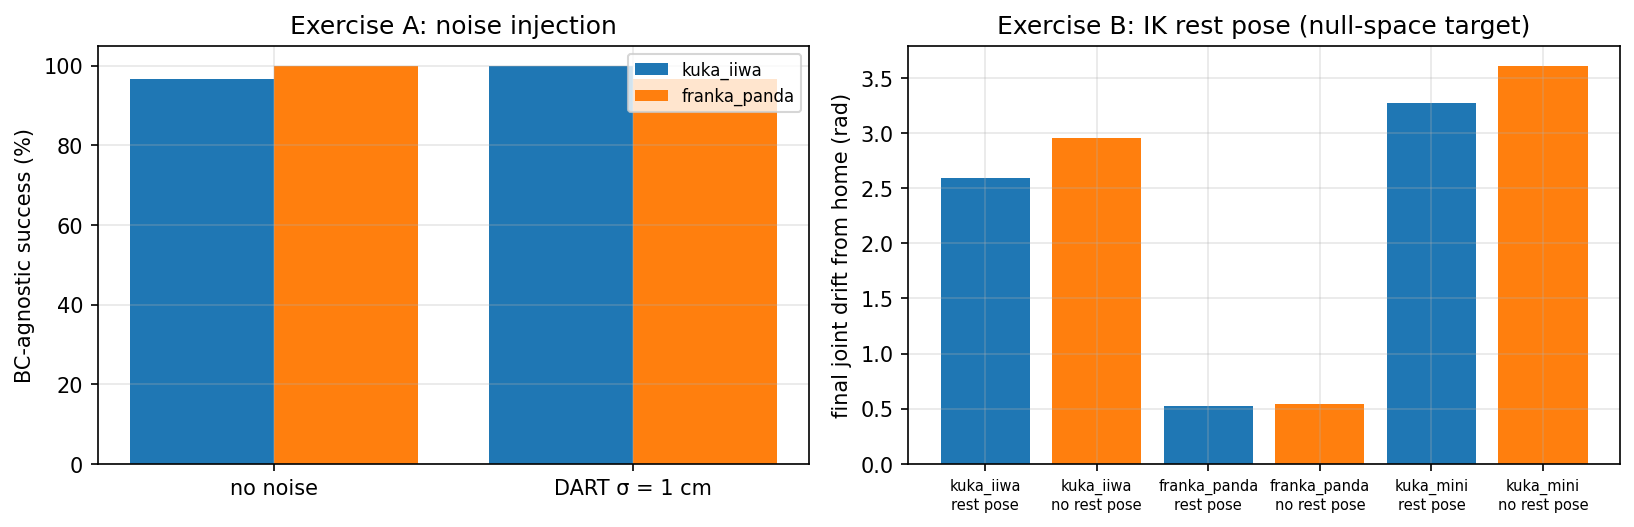

In [12]:
exA = []
for noise in (0.0, 0.01):
    obs, Y = collect(ARMS["kuka_iiwa"], 150, seed=300, noise=noise)
    pol = train_policy(obs, Y, proprio=False)
    exA.append({"dart_noise_m": noise,
                **{f"{n}_pct": round(100*success_rate(lambda r: run_policy(ARMS[n], pol, False, r), N_EVAL, 13), 1)
                   for n in ("kuka_iiwa", "franka_panda")}})
    print(exA[-1])
RESULTS["exA"] = exA

exB = []
for n in ("kuka_iiwa", "franka_panda", "kuka_mini"):
    for use_rest in (True, False):
        arm = Arm(n, use_rest_pose=use_rest); rng = np.random.default_rng(21); oks, drift = [], []
        for _ in range(N_EVAL):
            ok, _, _, _ = run_expert(arm, rng); oks.append(ok)
            drift.append(float(np.linalg.norm(arm.q() - arm.rest[:arm.dof])))
        exB.append({"robot": n, "rest_pose": use_rest, "success_pct": round(100*np.mean(oks), 1),
                    "joint_drift_rad": round(float(np.mean(drift)), 2)})
        print(exB[-1])
RESULTS["exB"] = exB
write_csv("exercises.csv", [{"exercise": "A", **r} for r in exA] + [{"exercise": "B", **r} for r in exB])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
xa = np.arange(2)
a1.bar(xa - 0.2, [r["kuka_iiwa_pct"] for r in exA], 0.4, label="kuka_iiwa")
a1.bar(xa + 0.2, [r["franka_panda_pct"] for r in exA], 0.4, label="franka_panda")
a1.set_xticks(xa); a1.set_xticklabels(["no noise", "DART σ = 1 cm"])
a1.set(ylabel="BC-agnostic success (%)", ylim=(0, 105), title="Exercise A: noise injection"); a1.legend(fontsize=8)
labels = [f"{r['robot']}\n{'rest pose' if r['rest_pose'] else 'no rest pose'}" for r in exB]
a2.bar(range(len(exB)), [r["joint_drift_rad"] for r in exB], color=["tab:blue" if r["rest_pose"] else "tab:orange" for r in exB])
a2.set_xticks(range(len(exB))); a2.set_xticklabels(labels, fontsize=7)
a2.set(ylabel="final joint drift from home (rad)", title="Exercise B: IK rest pose (null-space target)")
fig.tight_layout(); save_both(fig, "06_exercises.png"); plt.show()

In [13]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 6 figures in figs/
